# 04b · Temporal graph model on REAL data (Global Fishing Watch, southern Indian EEZ) — 5 YEARS (2021–2025)

This notebook trains the temporal graph-attention model on the **real** data downloaded in notebook 02 (2021–2025, 5 years). It loads the data from your Google Drive (`MyDrive/india-fishing-gnn-data/real_gfw`), so nothing is downloaded again.

**Why "forecast next week"?** There are no public labels of confirmed illegal fishing for Indian waters. Training on invented labels would be dishonest, so the model learns a task real data *can* check:

> From everything seen up to week *t*, how likely is each vessel, in week *t + 1*, to have an AIS-off gap, an encounter (with any vessel, or with a carrier), loitering, fishing inside a marine protected area, or fishing inside an EEZ that is not its own flag state's (for example an Indian boat in Sri Lankan waters, or a foreign boat in Indian waters)?

The **investigation priority** is a fixed, documented combination of these calibrated forecasts. It is an analyst's weighting, not a learned "illegality" label.

**Held-out evidence.** None of the following is ever given to the model as input or target. The notebook then checks whether high-priority vessel-weeks are followed by more of it:
- GFW's own *possible intentional AIS disabling* flag on the next week's gaps;
- **Sentinel-1 radar** detections of vessels that match no AIS, within 20 km of the next week's gaps;
- **Sentinel-1 radar** detections of vessels that match no AIS, within 5 km of where the vessel fished next week, on the same day (unidentified boats operating alongside it).

**The graph**
- **Nodes:** vessel × week. Only fishing-related vessels are kept (fishing, carrier, support and bunker vessels, plus any vessel that met one of them); pure merchant traffic is dropped.
- **Edges:**
  - each vessel's previous 1–3 active weeks (past → present only);
  - real encounters in the same week;
  - co-location: vessels active in the same 0.25° cell in the same week.

**Comparisons**
- persistence ("next week looks like this week");
- gradient-boosted trees;
- the same network without a graph;
- the network with temporal edges only;
- the full graph.

**Splits**
- **Time split (main):** train on the past (2021 to Mar 2025), validate on Apr–Jun 2025, test on Jul–Dec 2025 (the validation and test windows are unchanged from the 2-year run, so scores stay comparable), with a one-week embargo at each boundary.
- **Vessel split:** test vessels are never seen in training.

**Runtime:** **use a GPU** (Runtime → Change runtime type → T4 GPU). The full run takes about 20–40 min; `FAST_MODE = True` takes about 5–10 min. A CPU run is possible with `FAST_MODE` but is slow (about 1 h or more).

> ⚠️ Real data, real limits. Many small Indian boats have no AIS at all. Scores rank **what to look at first**, never who is guilty. Vessel identities stay anonymised.

In [1]:
# ---- Setup: works in Google Colab (CPU is enough) and locally --------------------
import os, sys, subprocess, pathlib, zipfile, glob
IN_COLAB = "google.colab" in sys.modules
REPO_URL = ""          # optional: URL of your GitHub copy of this repository
USE_DRIVE = False      # True = keep project + outputs on Google Drive (restart-safe)

if IN_COLAB:
    PROJECT_DIR = pathlib.Path("/content/india-fishing-gnn")
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = pathlib.Path("/content/drive/MyDrive/india-fishing-gnn")
    if not (PROJECT_DIR / "src").exists():
        if REPO_URL:
            subprocess.run(["git", "clone", "-q", REPO_URL, str(PROJECT_DIR)], check=True)
        else:
            # accepts renamed downloads such as "india-fishing-gnn (1).zip"
            zips = sorted(glob.glob("/content/india-fishing-gnn*.zip"), key=os.path.getmtime)
            if not zips:
                from google.colab import files
                print("Project zip not found - choose india-fishing-gnn.zip from your computer:")
                uploaded = files.upload()   # file picker appears below this cell
                zips = [os.path.abspath(n) for n in uploaded if n.endswith(".zip")]
            if not zips:
                raise FileNotFoundError("No project zip uploaded.")
            print("Extracting", zips[-1])
            zipfile.ZipFile(zips[-1]).extractall(PROJECT_DIR.parent)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(PROJECT_DIR / "requirements-colab.txt")], check=True)
else:
    PROJECT_DIR = pathlib.Path.cwd()
    while not (PROJECT_DIR / "src").exists() and PROJECT_DIR != PROJECT_DIR.parent:
        PROJECT_DIR = PROJECT_DIR.parent

os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))
print("Project directory:", PROJECT_DIR, "| Colab:", IN_COLAB)

Project zip not found - choose india-fishing-gnn.zip from your computer:


Saving india-fishing-gnn_5yr.zip to india-fishing-gnn_5yr.zip
Extracting /content/india-fishing-gnn_5yr.zip
Project directory: /content/india-fishing-gnn | Colab: True


## 0 · Mount Google Drive and find the saved real data

In [4]:
from pathlib import Path
DRIVE_DATA = Path("/content/drive/MyDrive/india-fishing-gnn-data")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
from src.real_model import find_real_dir
REAL_DIR = find_real_dir()
OUT = (DRIVE_DATA / "outputs_04b") if IN_COLAB else (PROJECT_DIR / "outputs" / "real_04b")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
print("real data:", REAL_DIR)
print("results will also be saved to:", OUT)
!ls -la {REAL_DIR}

Mounted at /content/drive
real data: /content/drive/MyDrive/india-fishing-gnn-data/real_gfw
results will also be saved to: /content/drive/MyDrive/india-fishing-gnn-data/outputs_04b
total 211794
drwx------ 2 root root      4096 Sep 28 12:53 .
drwx------ 4 root root      4096 Sep 28 12:53 ..
-rw------- 1 root root 165546014 Oct 13 07:02 events.parquet
-rw------- 1 root root  22672667 Oct 13 07:02 fishing_effort.parquet
-rw------- 1 root root   4303722 Oct 13 07:02 graph_edges.parquet
-rw------- 1 root root  12597319 Oct 13 07:02 graph_nodes_vessel_week.parquet
-rw------- 1 root root  10846129 Oct 13 07:01 _private_id_map.parquet
-rw------- 1 root root      1337 Oct 13 07:02 provenance.json
-rw------- 1 root root    348798 Sep 29 06:33 sar_all_vessels.parquet
-rw------- 1 root root    549901 Oct 13 07:02 sar_unmatched.parquet


## 1 · Settings

In [5]:
import json, warnings, time
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from src import real_model as rm
from src import visualization as viz
from src.config import FIGURE_DIR, METRIC_DIR

FAST_MODE = False            # True = 1 seed, time split only (about 5-10 min on a T4 GPU)
RUN_VESSEL_SPLIT = not FAST_MODE
DOWNLOAD_SAR_FOOTPRINT = True   # one-time (~10 min, needs GFW_API_TOKEN secret); cached on Drive afterwards
PROV = json.loads((REAL_DIR / "provenance.json").read_text()) if (REAL_DIR / "provenance.json").exists() else {}
START, END = PROV.get("start", "2021-01-01"), PROV.get("end", "2025-12-31")
BBOX = tuple(PROV.get("bbox_lat_lat_lon_lon", (5.0, 16.0, 70.0, 82.0)))
CFG = rm.RealConfig(seeds=(0,) if FAST_MODE else (0, 1, 2), study_start=START)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for p in (FIGURE_DIR, METRIC_DIR):
    p.mkdir(parents=True, exist_ok=True)
FIG = OUT / "figures"
print("device:", DEVICE, "| seeds:", CFG.seeds)
if DEVICE.type == "cpu":
    print("No GPU found. Runtime -> Change runtime type -> T4 GPU is strongly recommended.")
print(rm.REAL_MODEL_CAVEAT)

device: cuda | seeds: (0, 1, 2)
REAL DATA (Global Fishing Watch). Scores are an investigation PRIORITY derived from forecasts of next-week activity patterns. They are not evidence of illegal fishing; every alert needs human verification. Vessel identities are anonymised.


## 2a · Radar imaging footprint (one-time download)

Sentinel-1 does not photograph all of the open ocean every day. If there's no radar detection of an unidentified boat next to a vessel, that only means something where the satellite actually took a picture that day.

- **Imaging footprint:** this cell downloads radar detections of **all** vessels, including those matched to AIS. Any detection within 25 km on the same day proves the area was imaged.
- **Where it's used:** the radar evidence check in section 9 is evaluated only in those imaged places.
- **What it needs:** the `GFW_API_TOKEN` secret, as in notebook 02. The first run takes longer for 5 years (2024–2025 months are reused from the Drive cache; 2021–2023 download, roughly 15–20 min); after that the footprint is read from Drive.
- **Skipping it:** set `DOWNLOAD_SAR_FOOTPRINT = False`. The radar check is then reported without a coverage correction and is not reliable.

In [6]:
SAR_ALL_FILE = REAL_DIR / f"sar_all_vessels_{START}_{END}.parquet"   # one file per study period
sar_all = None
if SAR_ALL_FILE.exists():
    sar_all = pd.read_parquet(SAR_ALL_FILE)
elif DOWNLOAD_SAR_FOOTPRINT:
    try:
        from src.gfw_real import get_token, make_client, fetch_sar, bbox_polygon
        client = make_client(get_token())
        cache = (DRIVE_DATA / "gfw_raw_cache") if IN_COLAB else None
        kw = {"cache_dir": cache} if cache else {}
        sar_all = await fetch_sar(client, bbox_polygon(BBOX), START, END, unmatched_only=False, **kw)
        sar_all.to_parquet(SAR_ALL_FILE, index=False)
    except Exception as ex:
        print("Footprint download failed - continuing without it:", type(ex).__name__, ex)
print("radar footprint:", f"{len(sar_all):,} cell-days" if sar_all is not None else "not available")

Paste your Global Fishing Watch API token (input hidden): ··········
  SAR (all) 2021-01-01:  3941 cell-days
  SAR (all) 2021-02-01:  3678 cell-days
  SAR (all) 2021-03-01:  3447 cell-days
  SAR (all) 2021-04-01:  3020 cell-days
  SAR (all) 2021-05-01:  2637 cell-days
  SAR (all) 2021-06-01:  2017 cell-days
  SAR (all) 2021-07-01:  1775 cell-days
  SAR (all) 2021-08-01:  3557 cell-days
  SAR (all) 2021-09-01:  3432 cell-days
  SAR (all) 2021-10-01:  3931 cell-days
  SAR (all) 2021-11-01:  3682 cell-days
  SAR (all) 2021-12-01:  3930 cell-days
  SAR (all) 2022-01-01:  3831 cell-days
  SAR (all) 2022-02-01:  4251 cell-days
  SAR (all) 2022-03-01:  4023 cell-days
  SAR (all) 2022-04-01:  2863 cell-days
  SAR (all) 2022-05-01:  2980 cell-days
  SAR (all) 2022-06-01:  1893 cell-days
  SAR (all) 2022-07-01:  1713 cell-days
  SAR (all) 2022-08-01:  2297 cell-days
  SAR (all) 2022-09-01:  2604 cell-days
  SAR (all) 2022-10-01:  3018 cell-days
  SAR (all) 2022-11-01:  4038 cell-days
  SAR (all)

## 2 · Load and clean the real events

**Cleaning rules**
- A few GFW gap records span years (the raw maximum was about 48,000 h). These mean the vessel left the area or stopped transmitting for good, so gaps longer than **30 days** are not counted as gaps. They are kept only as a separate count.
- Single-event durations are capped at one week.
- Every encounter is given a row for **both** vessels.
- Events that started before the study period are dropped. These are a few very old port visits; without this step the weekly chart would start in 2014.

In [7]:
ev_raw, sar, _ = rm.load_real(REAL_DIR)
print(f"events loaded: {len(ev_raw):,} | SAR cell-days (no AIS match): {len(sar):,} | "
      f"SAR cell-days (all vessels, imaging footprint): {len(sar_all) if sar_all is not None else 'not available'}")
ev, rep = rm.clean_events(ev_raw, CFG)
ev = rm.add_sar_evidence(ev, sar, CFG.sar_radius_km, sar_all=sar_all)   # held-out evidence only
fe = ev.event_type.eq("fishing")
rep["fishing events in radar-imaged areas (same day)"] = int((fe & ev.sar_imaged).sum())
rep["...of which with an unmatched SAR detection within 5 km"] = int((fe & ev.sar_imaged & (ev.sar_near_event > 0)).sum())
display(pd.Series(rep, name="value").to_frame())
f = ev[ev.event_type.eq("fishing")]
print("Fishing events by flag: share inside an EEZ that is not the flag state's (sanity check)")
display(f.assign(flag=f.flag.fillna("unknown")).groupby("flag").agg(
    fishing_events=("event_id", "size"), share_outside_flag_eez=("outside_flag_eez", "mean"))
    .sort_values("fishing_events", ascending=False).head(8).round(3))
g = ev[ev.gap_valid]
display(g.gap_h.describe(percentiles=[.5, .9, .99]).round(1).rename("valid gap hours").to_frame().T)

events loaded: 1,878,474 | SAR cell-days (no AIS match): 136,950 | SAR cell-days (all vessels, imaging footprint): 181002


,value
events_in,1878474.0
events starting before the study period (dropped),1908.0
gaps,1004.0
gaps_valid_1h_30d,913.0
gaps_longer_than_30d (not used as gaps),91.0
gaps_shorter_than_min,0.0
max_raw_gap_h,30438.7
fishing events with known flag,548174.0
encounter_rows_after_mirroring,27026.0
fishing events in radar-imaged areas (same day),32104.0


Fishing events by flag: share inside an EEZ that is not the flag state's (sanity check)


,fishing_events,share_outside_flag_eez
flag,,
LKA,322549,0.042
IND,223739,0.002
None,6825,0.000
CHN,1258,1.000
KNA,282,1.000
TWN,124,1.000
SYC,82,1.000
JPN,26,1.000


,count,mean,std,min,50%,90%,99%,max
valid gap hours,913.0,85.2,109.6,12.0,48.2,174.4,610.5,718.3


## 3 · Keep fishing-related vessels (drop pure merchant traffic)

In [8]:
keep, vclass, sel = rm.select_vessels(ev, CFG)
display(sel)
ev = ev[ev.vessel_id.isin(keep)].reset_index(drop=True)
print(f"kept {len(keep):,} vessels and {len(ev):,} events")
display(ev.groupby("event_type").size().rename("events kept").to_frame())

reason,dropped (no fishing link),fishing-related,met a fishing-related vessel
class,,,
bunker,0,24,0
cargo_tanker,9989,0,0
carrier,0,32,0
fishing,0,14096,0
other,204781,44,2
passenger,614,0,0


kept 14,198 vessels and 995,433 events


,events kept
event_type,
encounter,27026
fishing,554999
gap,72
loitering,319027
port_visit,94309


## 4 · Vessel-week table: inputs, next-week targets, held-out evidence

vessel-weeks: 250,831 | with a next active week: 124,658


,share of vessel-weeks (next week)
y_gap,0.01%
y_encounter,5.06%
y_carrier_encounter,0.00%
y_loitering,62.44%
y_fishing_in_mpa,1.47%
y_fishing_outside_flag_eez,2.41%
e_intentional_gap,0.01%
e_sar_near_gap,0.00%
e_sar_near_fishing,3.36%


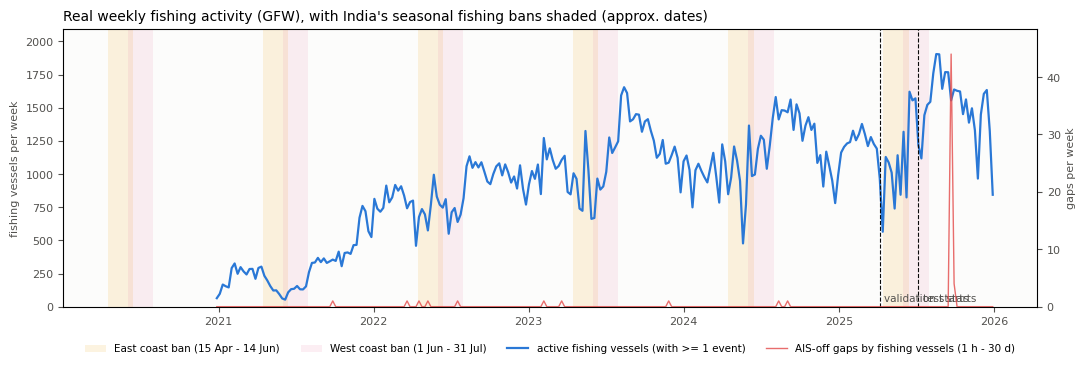

In [9]:
nodes = rm.weekly_table(ev, vclass, CFG)
print(f"vessel-weeks: {len(nodes):,} | with a next active week: {int(nodes.has_next.sum()):,}")
tcols = [f"y_{t}" for t in rm.TASKS]; ecols = [f"e_{k}" for k in rm.EVIDENCE]
rates = nodes[nodes.has_next][tcols + ecols].mean().rename("share of vessel-weeks (next week)")
display(rates.to_frame().style.format("{:.2%}"))
fig = viz.plot_weekly_activity(nodes, FIG / "real_weekly_activity.png",
                               split_lines={"validation starts": CFG.val_start, "test starts": CFG.test_start})
plt.show()

## 5 · Build the real temporal interaction graph

In [10]:
t0 = time.time()
G = rm.build_real_graph(nodes, ev, CFG)
display(rm.graph_summary(G).rename("count").to_frame())
_E = G["edge_index"].shape[1]
_gb = _E * CFG.hidden * 4 * 4 * CFG.layers / 1e9   # rough: ~4 edge-sized float tensors per GAT layer kept for backprop
print(f"{G['n']:,} nodes, {_E:,} edges -> roughly {_gb:.0f} GB of GPU memory for training (a T4 has 15 GB).")
if DEVICE.type == "cuda":
    _tot = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"GPU: {torch.cuda.get_device_name(0)}, {_tot:.0f} GB")
    if _gb > 0.8 * _tot:
        print("WARNING: likely out of memory. Lower CFG.max_total_edges (e.g. 3_000_000), CFG.temporal_lags to 2, or CFG.hidden to 32, then re-run this cell.")
print(f"built in {time.time() - t0:.0f}s | edge features: {rm.EDGE_COLS} + 8-d learned time encoding (lag in weeks)")

,count
nodes (vessel-weeks),250831
vessels,14198
fishing-vessel nodes,248879
nodes with a next week (have targets),124658
temporal edges,519041
encounter edges (directed),24414
co-location edges (directed),1048834
node features,41


250,831 nodes, 1,592,289 edges -> roughly 3 GB of GPU memory for training (a T4 has 15 GB).
GPU: Tesla T4, 16 GB
built in 1s | edge features: ['is_temporal', 'is_encounter', 'is_coloc', 'enc_log_dist', 'enc_log_dur', 'enc_speed', 'src_is_fishing', 'src_is_carrier'] + 8-d learned time encoding (lag in weeks)


## 6 · Leakage-safe splits

In [11]:
splits = {"time": rm.time_split(nodes, CFG)}
if RUN_VESSEL_SPLIT:
    splits["vessel"] = rm.vessel_split(nodes)
for name, (sp, gtrain) in splits.items():
    t = pd.DataFrame({"split": sp, "has_next": nodes.has_next})
    for c in tcols:
        t[c] = nodes[c] * nodes.has_next
    tab = t.groupby("split").agg(nodes=("has_next", "size"), with_target=("has_next", "sum"),
                                 **{c.replace("y_", "pos_"): (c, "sum") for c in tcols})
    print(f"--- {name} split")
    display(tab.astype(int))
    if name == "vessel":
        display(rm.cross_split_edges(G, sp).rename("count").to_frame())

--- time split


,nodes,with_target,pos_gap,pos_encounter,pos_carrier_encounter,pos_loitering,pos_fishing_in_mpa,pos_fishing_outside_flag_eez
split,,,,,,,,
embargo,2774,1291,0,68,0,828,2,55
test,39295,20176,10,1193,1,12442,254,594
train,195906,97055,2,4601,1,60518,1529,2196
val,12856,6136,0,449,0,4044,53,161


--- vessel split


,nodes,with_target,pos_gap,pos_encounter,pos_carrier_encounter,pos_loitering,pos_fishing_in_mpa,pos_fishing_outside_flag_eez
split,,,,,,,,
test,38393,19331,3,924,0,12084,297,465
train,175270,86705,8,4347,2,54271,1226,2116
val,37168,18622,1,1040,0,11477,315,425


,count
encounter edges crossing splits,11462
co-location edges crossing splits,491332


## 7 · Train and compare

- Every neural model is trained **inductively**: while fitting, it sees only the training part of the graph.
- Early stopping uses the validation macro PR-AUC.
- Forecasts are calibrated on validation (Platt scaling) before they are combined into the priority.

In [12]:
t0 = time.time()
res = rm.run_real_experiment(G, splits, CFG, DEVICE)
print(f"total training time: {(time.time() - t0) / 60:.1f} min")
runs, tsum, esum = rm.summarize(res)
for df, name in ((res["runs"], "runs"), (res["tasks"], "task_metrics"), (res["evidence"], "evidence_metrics")):
    df.to_csv(OUT / f"real_{name}.csv", index=False); df.to_csv(METRIC_DIR / f"real_{name}.csv", index=False)
display(runs.round(4))

[time] tasks with enough positives: ['encounter', 'loitering', 'fishing_in_mpa', 'fishing_outside_flag_eez']
  gradient boosting done in 25s
  Temporal GAT (full graph)              seed 0: val macro PR-AUC 0.3935 (64 epochs, 31s)
  Temporal GAT (full graph)              seed 1: val macro PR-AUC 0.4014 (150 epochs, 73s)
  Temporal GAT (full graph)              seed 2: val macro PR-AUC 0.3969 (150 epochs, 74s)
  Temporal GAT (temporal edges only)     seed 0: val macro PR-AUC 0.4076 (150 epochs, 41s)
  Temporal GAT (temporal edges only)     seed 1: val macro PR-AUC 0.4056 (150 epochs, 41s)
  Temporal GAT (temporal edges only)     seed 2: val macro PR-AUC 0.4018 (150 epochs, 41s)
  Same model, no graph (MLP)             seed 0: val macro PR-AUC 0.3416 (26 epochs, 1s)
  Same model, no graph (MLP)             seed 1: val macro PR-AUC 0.3681 (44 epochs, 2s)
  Same model, no graph (MLP)             seed 2: val macro PR-AUC 0.3913 (150 epochs, 9s)
[vessel] tasks with enough positives: ['encoun

,split,model,macro_pr_auc,macro_pr_auc_sd,macro_roc_auc,n_seeds
0,time,Persistence (this week = next week),0.3119,NaN,0.6405,1
1,time,Gradient boosting (no graph),0.4091,NaN,0.8320,1
2,time,Temporal GAT (full graph),0.4000,0.0083,0.8286,3
3,time,Temporal GAT (temporal edges only),0.4105,0.0040,0.8335,3
4,time,"Same model, no graph (MLP)",0.3541,0.0323,0.7765,3
5,vessel,Persistence (this week = next week),0.3574,NaN,0.6679,1
6,vessel,Gradient boosting (no graph),0.4900,NaN,0.8741,1
7,vessel,Temporal GAT (full graph),0.4626,0.0015,0.8735,3
8,vessel,Temporal GAT (temporal edges only),0.4635,0.0022,0.8726,3
9,vessel,"Same model, no graph (MLP)",0.4490,0.0007,0.8572,3


## 8 · Forecast quality per behaviour (test set)

model,Gradient boosting (no graph),Persistence (this week = next week),"Same model, no graph (MLP)",Temporal GAT (full graph),Temporal GAT (temporal edges only),base_rate
task,,,,,,
encounter,0.225,0.159,0.199,0.254,0.264,0.059
fishing_in_mpa,0.148,0.087,0.124,0.154,0.159,0.013
fishing_outside_flag_eez,0.489,0.271,0.341,0.421,0.444,0.029
loitering,0.773,0.731,0.752,0.771,0.774,0.617


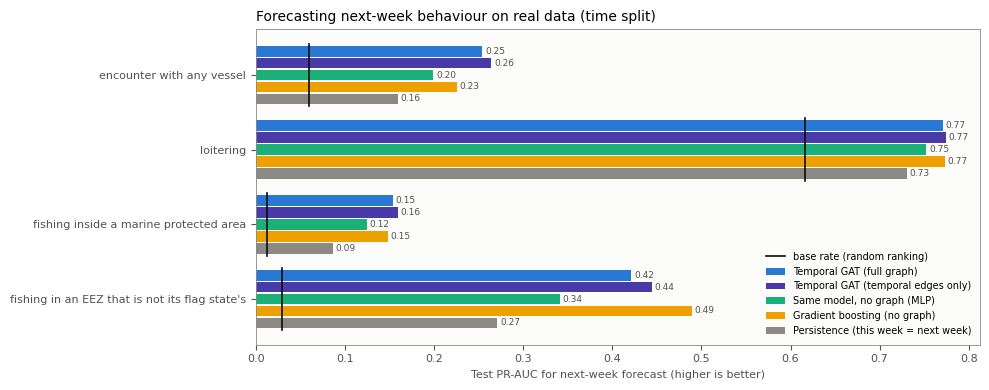

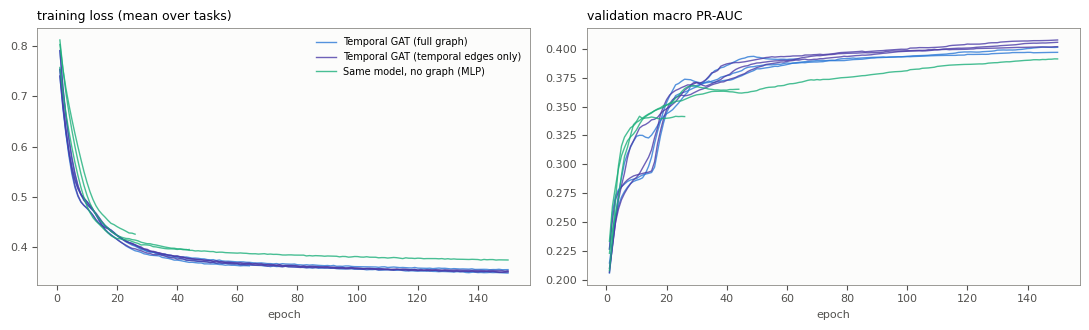

model,Gradient boosting (no graph),Persistence (this week = next week),"Same model, no graph (MLP)",Temporal GAT (full graph),Temporal GAT (temporal edges only),base_rate
task,,,,,,
encounter,0.317,0.206,0.291,0.309,0.306,0.048
fishing_in_mpa,0.263,0.096,0.198,0.210,0.204,0.015
fishing_outside_flag_eez,0.547,0.366,0.501,0.513,0.527,0.024
loitering,0.833,0.761,0.805,0.817,0.818,0.625


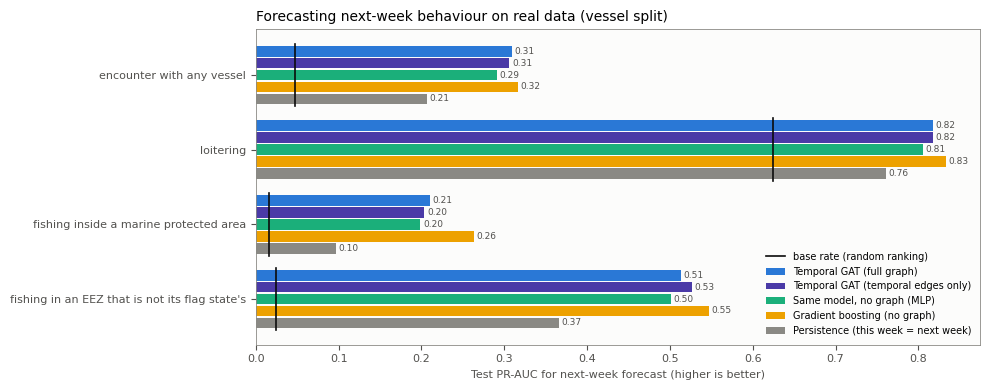

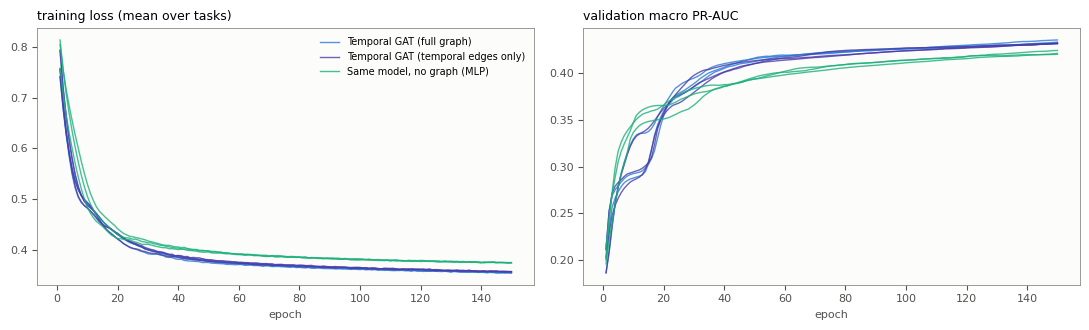

In [13]:
for sp in splits:
    display(tsum[tsum.split == sp].pivot(index="task", columns="model", values="pr_auc").round(3)
            .assign(base_rate=tsum[tsum.split == sp].groupby("task").base_rate.first().round(3)))
    fig = viz.plot_real_task_scores(tsum, sp, FIG / f"real_task_pr_auc_{sp}.png"); plt.show()
    fig = viz.plot_real_training(res["histories"], sp, FIG / f"real_training_{sp}.png"); plt.show()

## 9 · Does the priority point at held-out evidence?

- **Lift in the top 5%:** how many times more common the evidence is among the top 5% of vessel-weeks than on average. A lift of 1 means no better than random.
- **Activity-only reference:** a vessel that simply has many events will also have more of everything. The *Activity only* row shows how much of the lift comes from that alone, and a useful model must beat it.

model,Activity only (n events this week),Gradient boosting (no graph),Persistence (this week = next week),"Same model, no graph (MLP)",Temporal GAT (full graph),Temporal GAT (temporal edges only)
evidence,,,,,,
intentional_gap,2.0,2.0,4.0,4.67,2.00,2.00
sar_near_fishing,0.6,0.1,0.1,0.06,0.08,0.12
sar_near_gap,NaN,NaN,NaN,NaN,NaN,NaN


model,Activity only (n events this week),Gradient boosting (no graph),Persistence (this week = next week),"Same model, no graph (MLP)",Temporal GAT (full graph),Temporal GAT (temporal edges only),base_rate
evidence,,,,,,,
intentional_gap,0.001,0.002,0.001,0.002,0.001,0.001,0.0005
sar_near_fishing,0.228,0.172,0.215,0.171,0.169,0.172,0.2651
sar_near_gap,NaN,NaN,NaN,NaN,NaN,NaN,0.0000


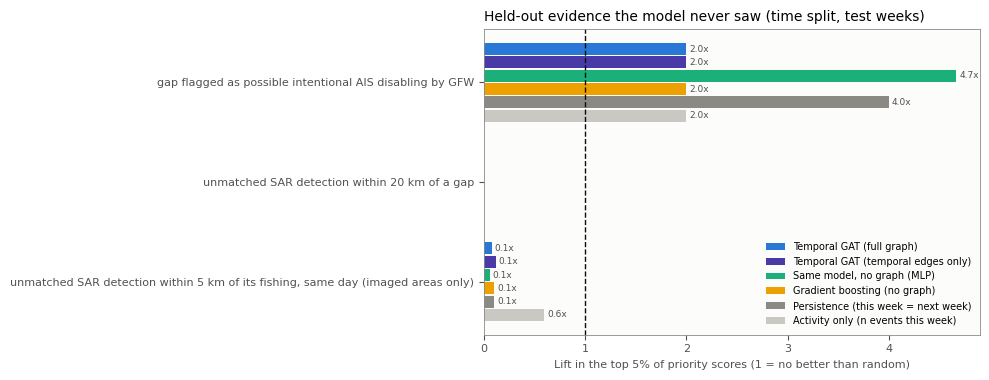

model,Activity only (n events this week),Gradient boosting (no graph),Persistence (this week = next week),"Same model, no graph (MLP)",Temporal GAT (full graph),Temporal GAT (temporal edges only)
evidence,,,,,,
intentional_gap,6.66,0.0,0.00,6.66,6.66,6.66
sar_near_fishing,0.84,0.1,0.13,0.10,0.06,0.11
sar_near_gap,NaN,NaN,NaN,NaN,NaN,NaN


model,Activity only (n events this week),Gradient boosting (no graph),Persistence (this week = next week),"Same model, no graph (MLP)",Temporal GAT (full graph),Temporal GAT (temporal edges only),base_rate
evidence,,,,,,,
intentional_gap,0.001,0.000,0.000,0.001,0.001,0.002,0.0002
sar_near_fishing,0.269,0.187,0.243,0.183,0.192,0.192,0.2747
sar_near_gap,NaN,NaN,NaN,NaN,NaN,NaN,0.0000


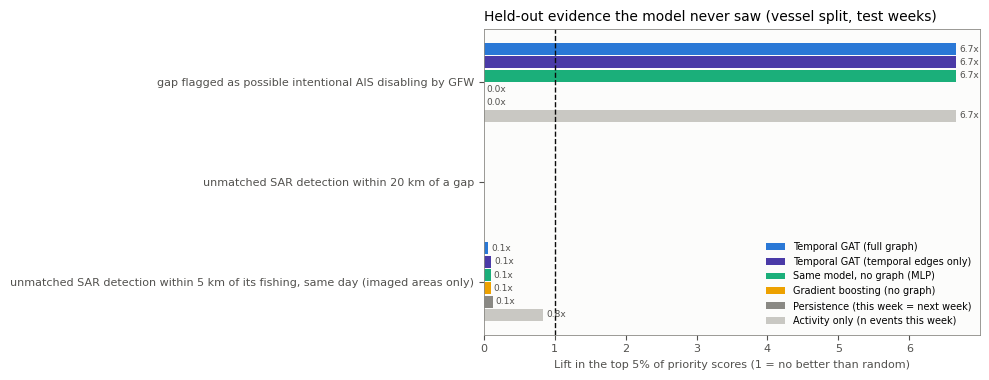

In [14]:
for sp in splits:
    e = esum[esum.split == sp]
    display(e.pivot(index="evidence", columns="model", values="lift_top5pct").round(2))
    display(e.pivot(index="evidence", columns="model", values="pr_auc").round(3)
            .assign(base_rate=e.groupby("evidence").base_rate.first().round(4)))
    fig = viz.plot_evidence_lift(esum, sp, FIG / f"real_evidence_lift_{sp}.png"); plt.show()

## 10 · Does the graph help?

- The full graph is compared against the *same* network without a graph, over all test vessel-weeks.
- It is also compared on the subgroup where the graph carries information: vessel-weeks with a real encounter or co-located vessels.

In [15]:
s, d = G["edge_index"]; et = G["edge_type"]
has_social = np.zeros(G["n"], bool); has_social[d[et > 0]] = True
rows = []
for sp_name, (sp, _) in splits.items():
    for model in ("Temporal GAT (full graph)", "Temporal GAT (temporal edges only)", "Same model, no graph (MLP)",
                  "Gradient boosting (no graph)"):
        for (spn, m, seed), p in res["preds"].items():
            if spn != sp_name or m != model:
                continue
            for grp_name, grp in (("all test vessel-weeks", np.ones(G["n"], bool)), ("with encounter / co-location neighbours", has_social)):
                sub = np.where(grp, sp, "other")
                tm = rm.task_metrics(p["P"], G, sub, p["tasks"])
                rows.append({"split": sp_name, "model": model, "seed": seed, "group": grp_name, "macro_pr_auc": tm.pr_auc.mean()})
gh = pd.DataFrame(rows).groupby(["split", "group", "model"]).macro_pr_auc.agg(["mean", "std"]).round(4)
gh.to_csv(OUT / "real_graph_help.csv"); display(gh)

mean     std
split  group                                   model                                             
time   all test vessel-weeks                   Gradient boosting (no graph)        0.4091     NaN
                                               Same model, no graph (MLP)          0.3541  0.0323
                                               Temporal GAT (full graph)           0.4000  0.0083
                                               Temporal GAT (temporal edges only)  0.4105  0.0040
       with encounter / co-location neighbours Gradient boosting (no graph)        0.4055     NaN
                                               Same model, no graph (MLP)          0.3532  0.0335
                                               Temporal GAT (full graph)           0.3994  0.0084
                                               Temporal GAT (temporal edges only)  0.4091  0.0039
vessel all test vessel-weeks                   Gradient boosting (no graph)        0.4900     NaN
                                               Same model, no graph (MLP)          0.4490  0.0007
                                               Temporal GAT (full graph)           0.4626  0.0015
                                               Temporal GAT (temporal edges only)  0.4635  0.0022
       with encounter / co-location neighbours Gradient boosting (no graph)        0.4813     NaN
                                               Same model, no graph (MLP)          0.4403  0.0005
                                               Temporal GAT (full graph)           0.4550  0.0014
                                               Temporal GAT (temporal edges only)  0.4541  0.0017

## 11 · Investigation-priority alerts (test weeks, time split)

In [16]:
best = rm.best_seed(res, "time", "Temporal GAT (full graph)")
alerts = rm.alert_table(G, best, splits["time"][0], top=50, weights=CFG.priority_weights)
rm.alerts_json(alerts, OUT / "real_alerts_top50.json",
               {"model": "Temporal GAT (full graph)", "split": "time", "period": f"test weeks from {CFG.test_start}",
                "priority_weights": CFG.priority_weights})
alerts.to_csv(OUT / "real_alerts_top50.csv", index=False)
show = ["rank", "vessel_id", "vessel_class", "week", "lat", "lon", "priority", "main_driver",
        "this_week_n_gaps", "this_week_n_enc", "next_week_observed"] + [c for c in alerts if c.startswith("heldout_")]
display(alerts[show].head(25))
print("share of top-50 whose next week showed held-out evidence:",
      alerts[[c for c in alerts if c.startswith("heldout_")]].any(axis=1).mean().round(3))

,rank,vessel_id,vessel_class,week,lat,lon,priority,main_driver,this_week_n_gaps,this_week_n_enc,next_week_observed,heldout_intentional_gap,heldout_sar_near_gap,heldout_sar_near_fishing
0,1,vessel_########,fishing,2025-12-08,6.0,80.7,0.800,fishing in an EEZ that is not its flag state's,0.0,1.0,fishing_outside_flag_eez,False,False,False
1,2,vessel_########,fishing,2025-12-01,6.4,77.6,0.733,fishing in an EEZ that is not its flag state's,0.0,0.0,encounter,False,False,False
2,3,vessel_########,fishing,2025-09-29,6.7,77.8,0.727,fishing in an EEZ that is not its flag state's,0.0,0.0,fishing_outside_flag_eez,False,False,False
3,4,vessel_########,fishing,2025-10-20,7.4,72.9,0.721,fishing in an EEZ that is not its flag state's,0.0,0.0,"loitering, fishing_outside_flag_eez",False,False,False
4,5,vessel_########,fishing,2025-10-27,5.9,79.9,0.713,fishing in an EEZ that is not its flag state's,0.0,2.0,"loitering, fishing_outside_flag_eez",False,False,False
5,6,vessel_########,fishing,2025-11-24,6.6,77.6,0.712,fishing in an EEZ that is not its flag state's,0.0,1.0,encounter,False,False,False
6,7,vessel_########,fishing,2025-11-03,6.8,78.4,0.711,fishing in an EEZ that is not its flag state's,0.0,0.0,fishing_outside_flag_eez,False,False,False
7,8,vessel_########,fishing,2025-07-07,5.9,80.5,0.708,fishing in an EEZ that is not its flag state's,0.0,0.0,"loitering, fishing_outside_flag_eez",False,False,False
8,9,vessel_########,fishing,2025-12-08,7.2,75.7,0.707,fishing in an EEZ that is not its flag state's,0.0,0.0,no flagged behaviour,False,False,False
9,10,vessel_########,fishing,2025-11-17,7.6,73.4,0.701,fishing in an EEZ that is not its flag state's,0.0,0.0,"loitering, fishing_outside_flag_eez",False,False,False


share of top-50 whose next week showed held-out evidence: 0.0


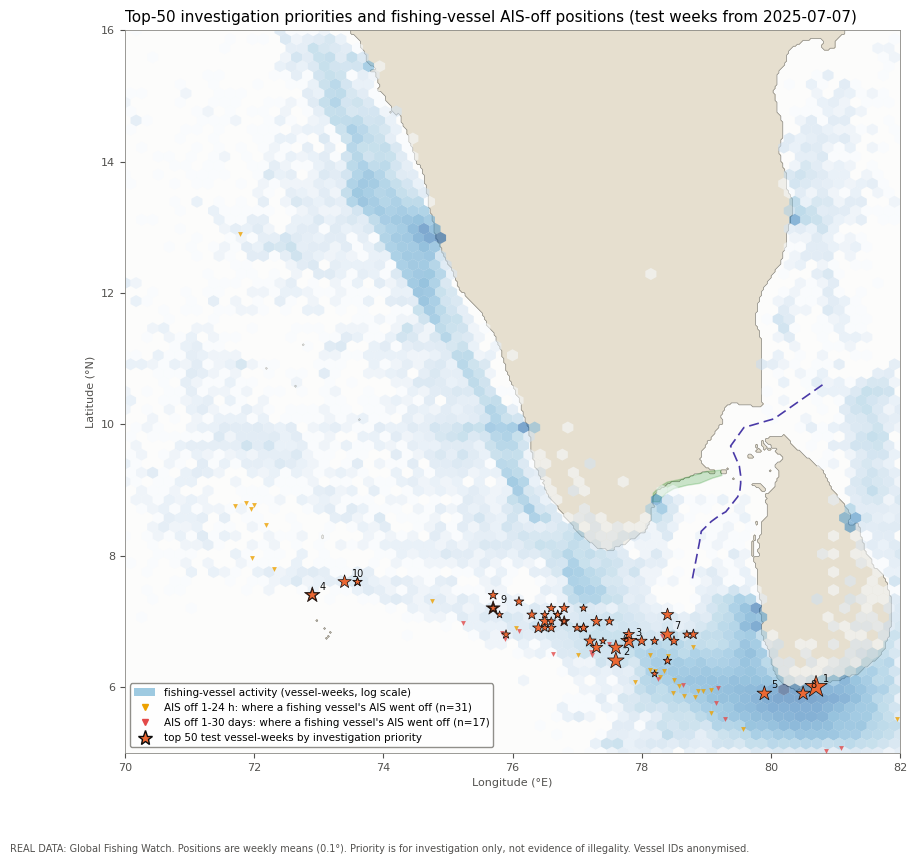

In [17]:
from src.india_layers import get_layers
prov = json.loads((REAL_DIR / "provenance.json").read_text()) if (REAL_DIR / "provenance.json").exists() else {}
bbox = tuple(prov.get("bbox_lat_lat_lon_lon", (5.0, 16.0, 70.0, 82.0)))
test_weeks = nodes.week >= pd.Timestamp(CFG.test_start)
fg = ev[ev.gap_valid & ev.vclass.eq("fishing") & (ev.week >= pd.Timestamp(CFG.test_start))]
fg = fg.dropna(subset=["off_lat"]) if "off_lat" in fg else fg.iloc[:0]
fig = viz.plot_real_alerts_map(nodes[test_weeks], alerts, fg, bbox, layers=get_layers("IN-GOM"),
                               title=f"Top-50 investigation priorities and fishing-vessel AIS-off positions (test weeks from {CFG.test_start})",
                               path=FIG / "real_alerts_map.png")
plt.show()

## 12 · Save summary (to the project and to Drive)

In [18]:
import shutil
summary = {
    "notebook": "04b_real_graph_model", "data": "Global Fishing Watch (real)", "caveat": rm.REAL_MODEL_CAVEAT,
    "device": str(DEVICE), "config": {k: v for k, v in vars(CFG).items()}, "cleaning": rep,
    "graph": rm.graph_summary(G).to_dict(),
    "models_mean": runs.to_dict("records"),
    "tasks_mean": tsum.to_dict("records"),
    "evidence_mean": esum.to_dict("records"),
}
(OUT / "real_model_summary.json").write_text(json.dumps(summary, indent=2, default=str))
shutil.copy(OUT / "real_model_summary.json", METRIC_DIR / "real_model_summary.json")
for f in FIG.glob("real_*.png"):
    shutil.copy(f, FIGURE_DIR / f.name)
print("saved:", *sorted(p.name for p in OUT.glob("*.*")), sep="\n  ")

saved:
  real_alerts_top50.csv
  real_alerts_top50.json
  real_evidence_metrics.csv
  real_graph_help.csv
  real_model_summary.json
  real_runs.csv
  real_task_metrics.csv


## How to read the results

**Questions the tables answer**
1. **Can real next-week behaviour be forecast at all?** Compare each model's PR-AUC with the base rate (the black tick). Persistence is the bar to beat: many vessels simply repeat what they did last week.
2. **Does the graph add anything?** Compare *Temporal GAT (full graph)* with the *no graph* and *temporal edges only* versions, overall and on vessel-weeks with neighbours (section 10). If they tie, the honest conclusion is that the encounter and co-location structure adds little beyond each vessel's own history on this data.
3. **Does the priority point at independent evidence?** Section 9 answers this. A lift above the *Activity only* reference means the model finds more than just the busiest vessels.

**Can conclude:** how well real vessel behaviour in the southern Indian EEZ can be forecast from GFW events, whether graph structure helps, and whether the resulting priority is enriched for independent radar and GFW risk evidence.

**Cannot conclude:**
- that any vessel acted illegally: gaps, encounters and fishing in a neighbouring EEZ all have lawful explanations (coverage, transhipment licences, access agreements);
- anything about boats without AIS, except indirectly through radar;
- that attention weights explain decisions. Milestone 4 adds proper explanations (GNNExplainer, SHAP, counterfactuals) for these alerts.

Attribution: data from **Global Fishing Watch**, non-commercial use.